In [1]:
import pandas as pd 
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
countydf = pd.read_excel(r'C:\Users\davis\OneDrive\Data Sci\DTSC2302\countysheets.xlsx', sheet_name=None)

In [3]:
df2022 = countydf['2022county']
# df2022.head()
df2023 = countydf['2023county']
# df2023.head()
df2024 = countydf['2024county']
# df2024.head()
df2025 = countydf['2025county']
# df2025.head()
df2026 = countydf['2026county']
# df2026.head()

In [4]:
df2026.head(-1)

,GEOTYPE,NAME,county_type,WDB,COG,gradeA,pop_county,pzone,pzsub,lea_num,...,topempl_2,topemp_range_2,topempl_3,topemp_range_3,starjob_1,starjob_growth_1,starjob_2,starjob_growth_2,starjob_3,starjob_growth_3
0,County,Alamance County,Suburban,Piedmont Triad Regional,Piedmont Triad Regional Council,1,187982,Piedmont Triad,Greensboro,1,...,Alamance-Burlington School System,1000+,Alamance Regional Medical Center,1000+,Nurse Practitioners,0.0414,Medical and Health Services Managers,0.0259,Physician Assistants,0.0253
1,County,Alexander County,Rural - Metro,Western Piedmont,Western Piedmont Council of Governments,1,36732,Northwest,Hickory,1,...,Craftmaster Furniture,500-999,Alexander County,250-499,Nurse Practitioners,0.0380,Physician Assistants,0.0248,Medical and Health Services Managers,0.0223
2,County,Alleghany County,Rural - Non-Metro,High Country,High Country Council of Governments,0,11638,Northwest,Boone-Wilkesboro,1,...,Roaring Gap Club,100-249,Parkdale Mills,100-249,Medical Equipment Repairers,0.0328,Nurse Practitioners,0.0305,"Health Specialties Teachers, Postsecondary",0.0259
3,County,Anson County,Rural - Metro,Centralina,Centralina Regional Council,0,21968,Southwest,Charlotte,1,...,NC Department of Adult Corrections,250-499,County of Anson,250-499,Nurse Practitioners,0.0534,Physician Assistants,0.0368,Medical and Health Services Managers,0.0359
4,County,Ashe County,Rural - Non-Metro,High Country,High Country Council of Governments,1,27014,Northwest,Boone-Wilkesboro,1,...,Horton Emergency Vehicles Company,250-499,General Electric Company,250-499,Medical Equipment Repairers,0.0328,Nurse Practitioners,0.0305,"Health Specialties Teachers, Postsecondary",0.0259
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,County,Watauga County,Rural - Non-Metro,High Country,High Country Council of Governments,0,55213,Northwest,Boone-Wilkesboro,1,...,Appalachian Regional Healthcare System,1000+,Samaritans Purse,500-999,Medical Equipment Repairers,0.0328,Nurse Practitioners,0.0305,"Health Specialties Teachers, Postsecondary",0.0259
95,County,Wayne County,Rural - Metro,Eastern Carolina,Eastern Carolina Council of Governments,3,120861,Southeast,Goldsboro-Kinston,1,...,Wayne Memorial Hospital,1000+,NC Dept of Health & Human Services,1000+,Nurse Practitioners,0.0269,Industrial Machinery Mechanics,0.0195,Chefs and Head Cooks,0.0188
96,County,Wilkes County,Rural - Non-Metro,High Country,High Country Council of Governments,1,65995,Northwest,Boone-Wilkesboro,1,...,Wilkes County Board of Education,500-999,Wilkes County,500-999,Medical Equipment Repairers,0.0328,Nurse Practitioners,0.0305,"Health Specialties Teachers, Postsecondary",0.0259
97,County,Wilson County,Rural - Non-Metro,Turning Point,Upper Coastal Plain Council of Governments,2,81209,North Central,Rocky Mount-Wilson,1,...,Truist Bank,1000+,Kidde Technologies,1000+,Nurse Practitioners,0.0329,Veterinarians,0.0240,Data Scientists,0.0229


In [ ]:
df2026.columns

Index(['GEOTYPE', 'NAME', 'county_type', 'WDB', 'COG', 'gradeA', 'pop_county',
       'pzone', 'pzsub', 'lea_num',
       ...
       'topemp_range_2', 'topempl_3', 'topemp_range_3', 'starjob_1',
       'starjob_growth_1', 'starjob_2', 'starjob_growth_2', 'starjob_3',
       'starjob_growth_3', 'is_rural'],
      dtype='str', length=134)

In [15]:
aratio = df2026["gradeA"]/df2026["school_num_trad"]
degree_to_gen_pop = df2026['any_degree_number']/df2026['pop_county']
log_medhhinc = np.log(df2026["medhhinc"])
log_any_degree_number = np.log(df2026["any_degree_number"])
log_k13_total = np.log(df2026["k13_total"])
log_ap_plus_number = np.log(df2026["ap_plus_number"])
log_no_degree_number = np.log(df2026["no_degree_number"])
log_pop_county = np.log(df2026["pop_county"])
ratioap = df2026['ap_plus_number']/df2026['pop_county']
log_home = np.log(df2026['home_owners'])
log_ratioap = np.log1p(ratioap)






In [ ]:
model2026 = smf.wls(formula="gradeA ~ medhhinc + home_owners + any_degree_number + k13_total + ap_plus_number", data=df2026, missing='drop').fit()
print(model2026.summary())

                            WLS Regression Results                            
Dep. Variable:                 gradeA   R-squared:                       0.906
Model:                            WLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     121.9
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           6.48e-37
Time:                        18:21:29   Log-Likelihood:                -157.14
No. Observations:                  83   AIC:                             328.3
Df Residuals:                      76   BIC:                             345.2
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -3.9769      2.35

In [7]:
model2026 = smf.ols(formula="gradeA ~ log_medhhinc + home_owners + any_degree_number + k13_total + ap_plus_number", data=df2026, missing='drop').fit()
print(model2026.summary())

                            OLS Regression Results                            
Dep. Variable:                 gradeA   R-squared:                       0.906
Model:                            OLS   Adj. R-squared:                  0.900
Method:                 Least Squares   F-statistic:                     148.2
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           5.00e-38
Time:                        17:43:09   Log-Likelihood:                -157.13
No. Observations:                  83   AIC:                             326.3
Df Residuals:                      77   BIC:                             340.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             3.5886     13.17

In [8]:
model2026 = smf.wls(formula="aratio ~ medhhinc + home_owners + log_k13_total + log_ap_plus_number + degree_to_gen_pop", data=df2026, missing='drop').fit()
print(model2026.summary())

                            WLS Regression Results                            
Dep. Variable:                 aratio   R-squared:                       0.153
Model:                            WLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     2.775
Date:                Fri, 20 Nov 2026   Prob (F-statistic):             0.0234
Time:                        17:43:09   Log-Likelihood:                 116.30
No. Observations:                  83   AIC:                            -220.6
Df Residuals:                      77   BIC:                            -206.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.0814      0

In [9]:
model2026 = smf.wls(formula="gradeA ~ log_medhhinc + log_k13_total + log_ap_plus_number + degree_to_gen_pop + ratioap + C(county_type)", data=df2026, missing='drop').fit(cov_type='HC3')
print(model2026.summary())

                            WLS Regression Results                            
Dep. Variable:                 gradeA   R-squared:                       0.620
Model:                            WLS   Adj. R-squared:                  0.579
Method:                 Least Squares   F-statistic:                     2.641
Date:                Fri, 20 Nov 2026   Prob (F-statistic):             0.0133
Time:                        17:43:09   Log-Likelihood:                -215.03
No. Observations:                  83   AIC:                             448.1
Df Residuals:                      74   BIC:                             469.8
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

In [28]:
df2026.county_type.value_counts()

county_type
Rural - Non-Metro    50
Rural - Metro        28
Suburban             16
Urban                 6
Name: count, dtype: int64

In [33]:
df2026['is_rural'] = (df2026['county_type'] == 'Rural - Non-Metro').astype(int).copy()

In [52]:
model5 = smf.ols(formula='aratio ~ log_medhhinc + log_ap_plus_number + log_k13_total + is_rural + hs_dropout_rate', data=df2026, missing='drop').fit(cov_type='HC3')
print(model5.summary())

                            OLS Regression Results                            
Dep. Variable:                 aratio   R-squared:                       0.184
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     1.797
Date:                Fri, 20 Nov 2026   Prob (F-statistic):              0.123
Time:                        18:22:52   Log-Likelihood:                 117.88
No. Observations:                  83   AIC:                            -223.8
Df Residuals:                      77   BIC:                            -209.2
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -1.8726      0

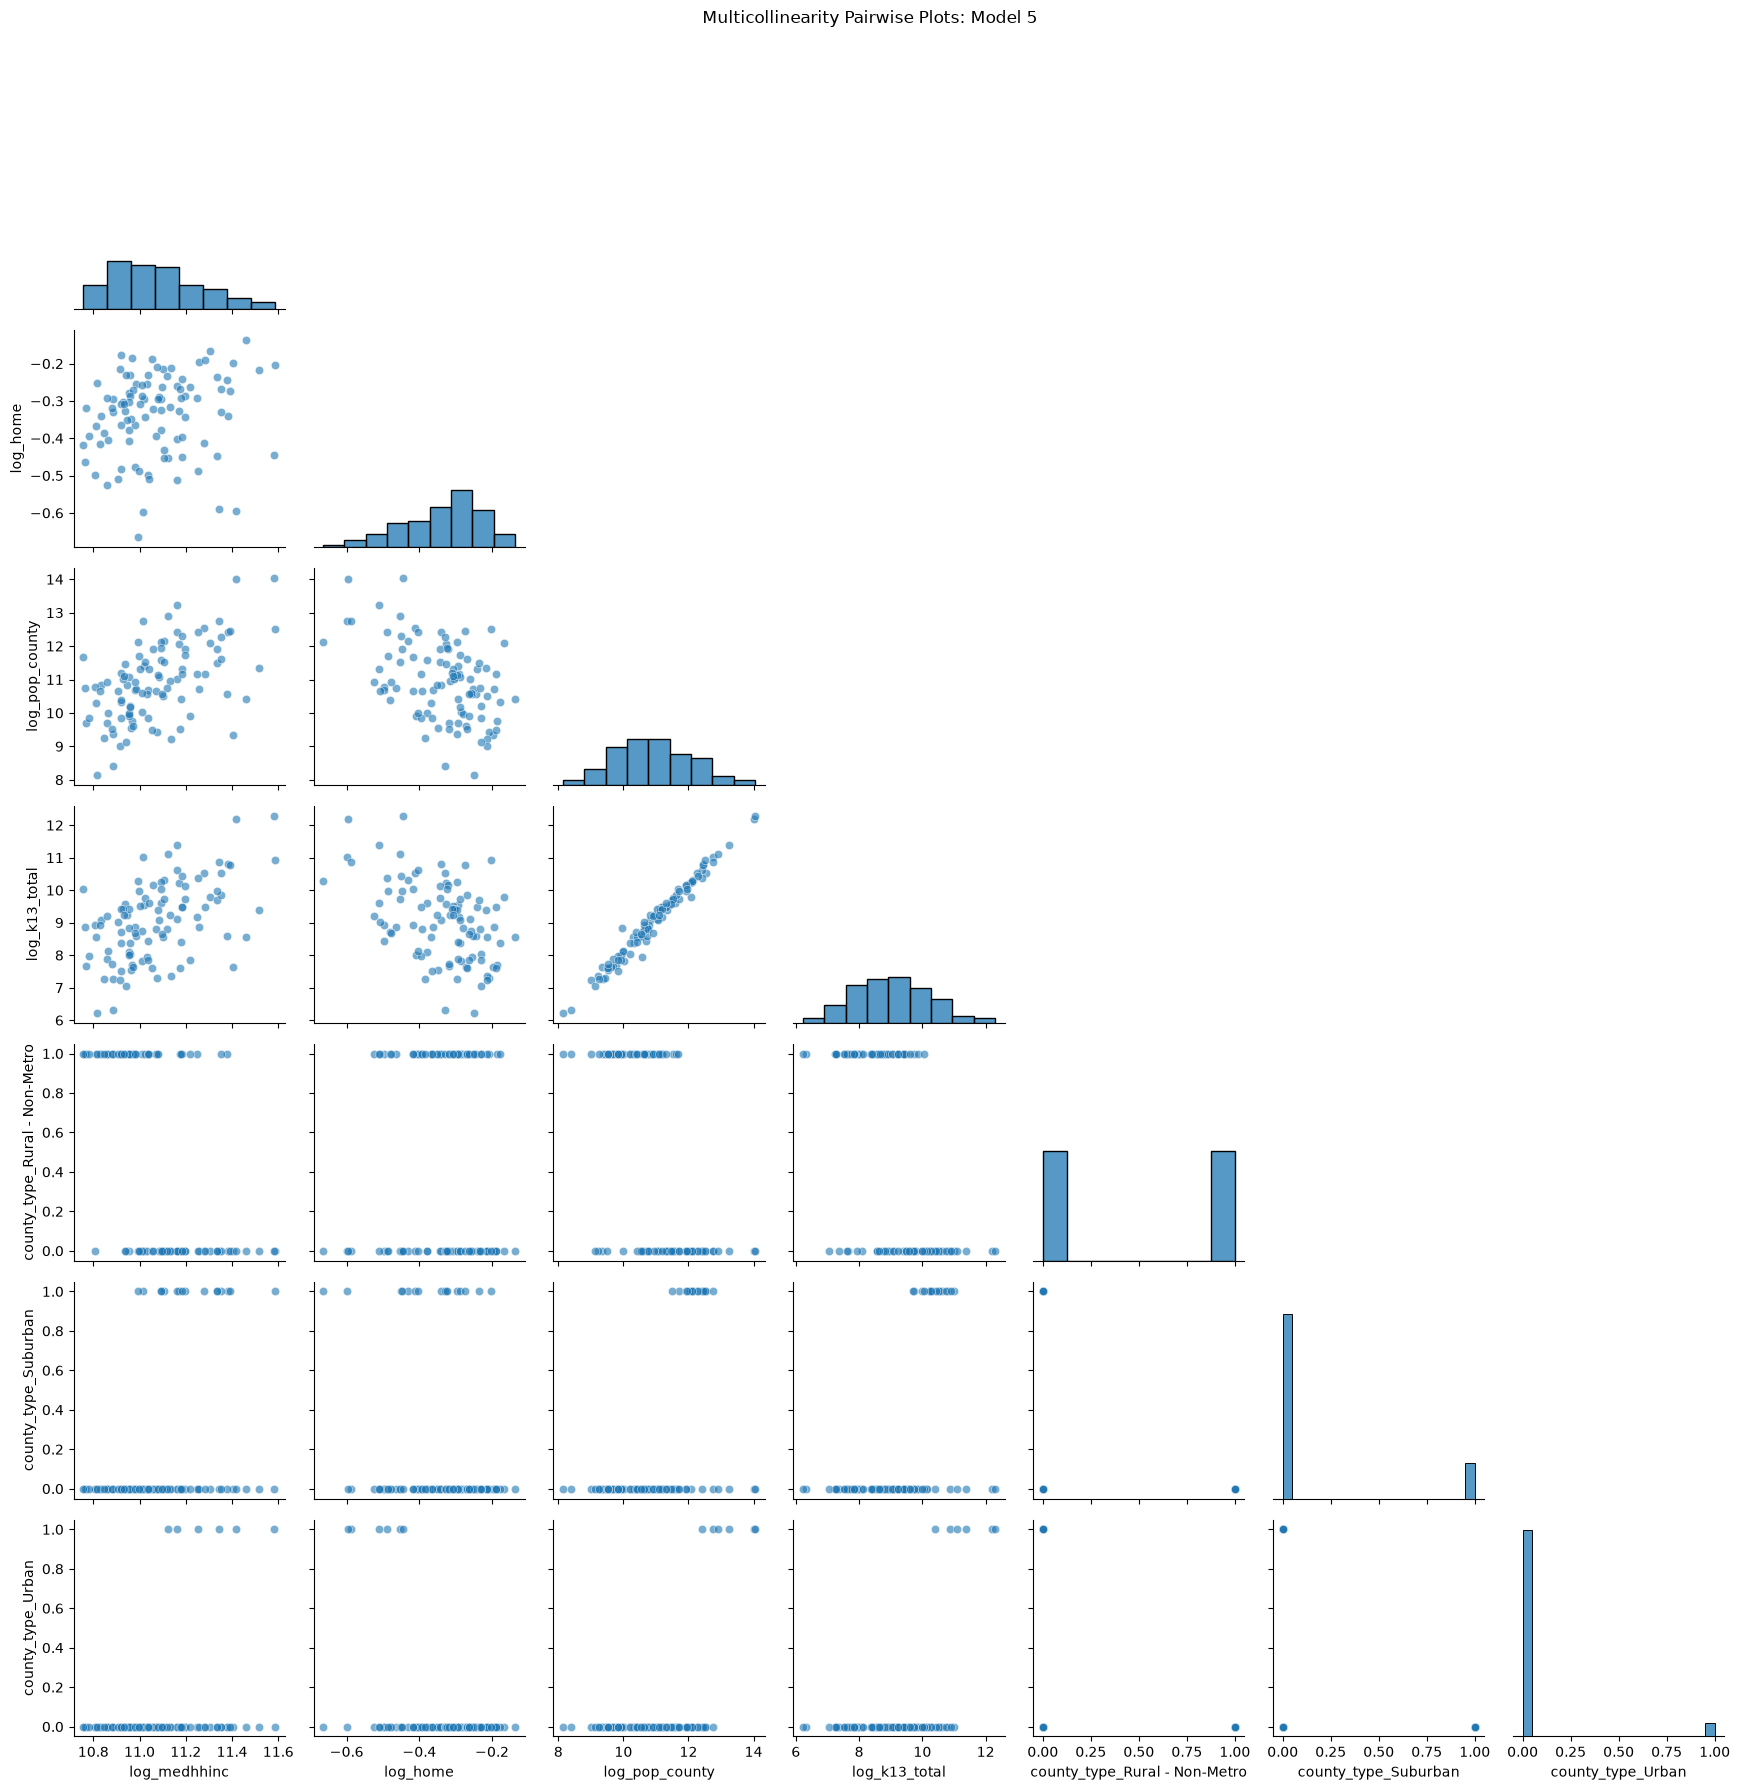

                        Variable        VIF
2                 log_pop_county  48.076021
3                  log_k13_total  43.921721
0                   log_medhhinc   2.398183
1                       log_home   2.163481
6              county_type_Urban   2.086603
5           county_type_Suburban   1.887436
4  county_type_Rural - Non-Metro   1.805340


C:\Users\davis\AppData\Local\Temp\ipykernel_24136\3854058208.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


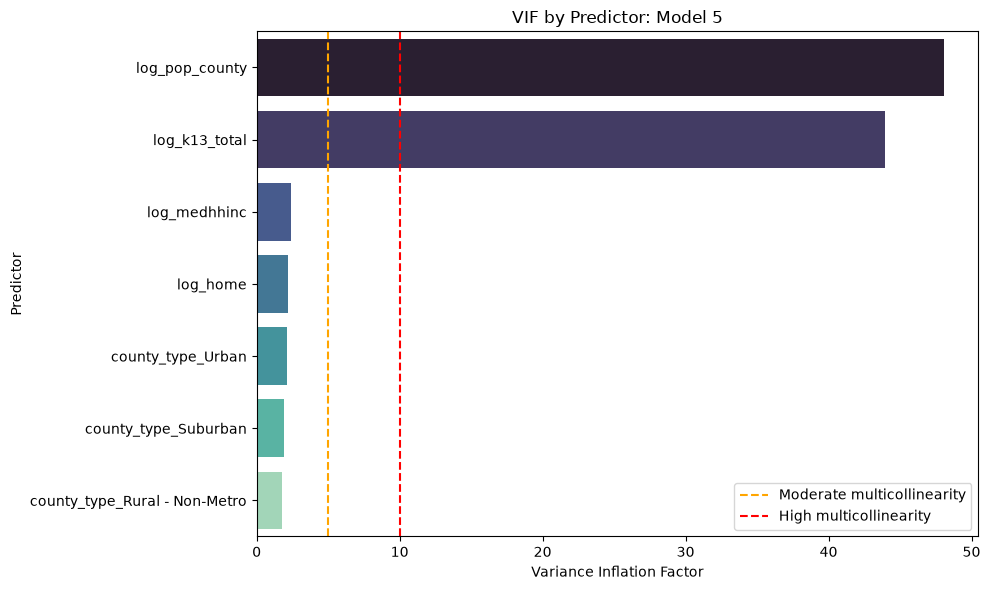

In [35]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Prepare the model variables and clean the data
model5_data = pd.DataFrame({
    "aratio": aratio,
    "log_medhhinc": log_medhhinc,
    "log_home": log_home,
    "log_pop_county": log_pop_county,
    "log_k13_total": log_k13_total,
    "county_type": df2026["county_type"],
}).replace([np.inf, -np.inf], np.nan).dropna()

model5_predictors = pd.get_dummies(
    model5_data.drop(columns="aratio"),
    columns=["county_type"],
    drop_first=True,
    dtype=float
)

# Pairwise scatter plots for model predictors
sns.pairplot(
    model5_predictors,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.6}
)
plt.suptitle("Multicollinearity Pairwise Plots: Model 5", y=1.02)
plt.tight_layout()
plt.show()

# Calculate VIF for every predictor
vif_values = pd.DataFrame({
    "Variable": model5_predictors.columns,
    "VIF": [
        variance_inflation_factor(model5_predictors.values, i)
        for i in range(model5_predictors.shape[1])
    ]
}).sort_values("VIF", ascending=False)

print(vif_values)

# Plot VIF values
plt.figure(figsize=(10, 6))
sns.barplot(
    data=vif_values,
    x="VIF",
    y="Variable",
    palette="mako"
)
plt.axvline(5, color="orange", linestyle="--", label="Moderate multicollinearity")
plt.axvline(10, color="red", linestyle="--", label="High multicollinearity")
plt.title("VIF by Predictor: Model 5")
plt.xlabel("Variance Inflation Factor")
plt.ylabel("Predictor")
plt.legend()
plt.tight_layout()
plt.show()

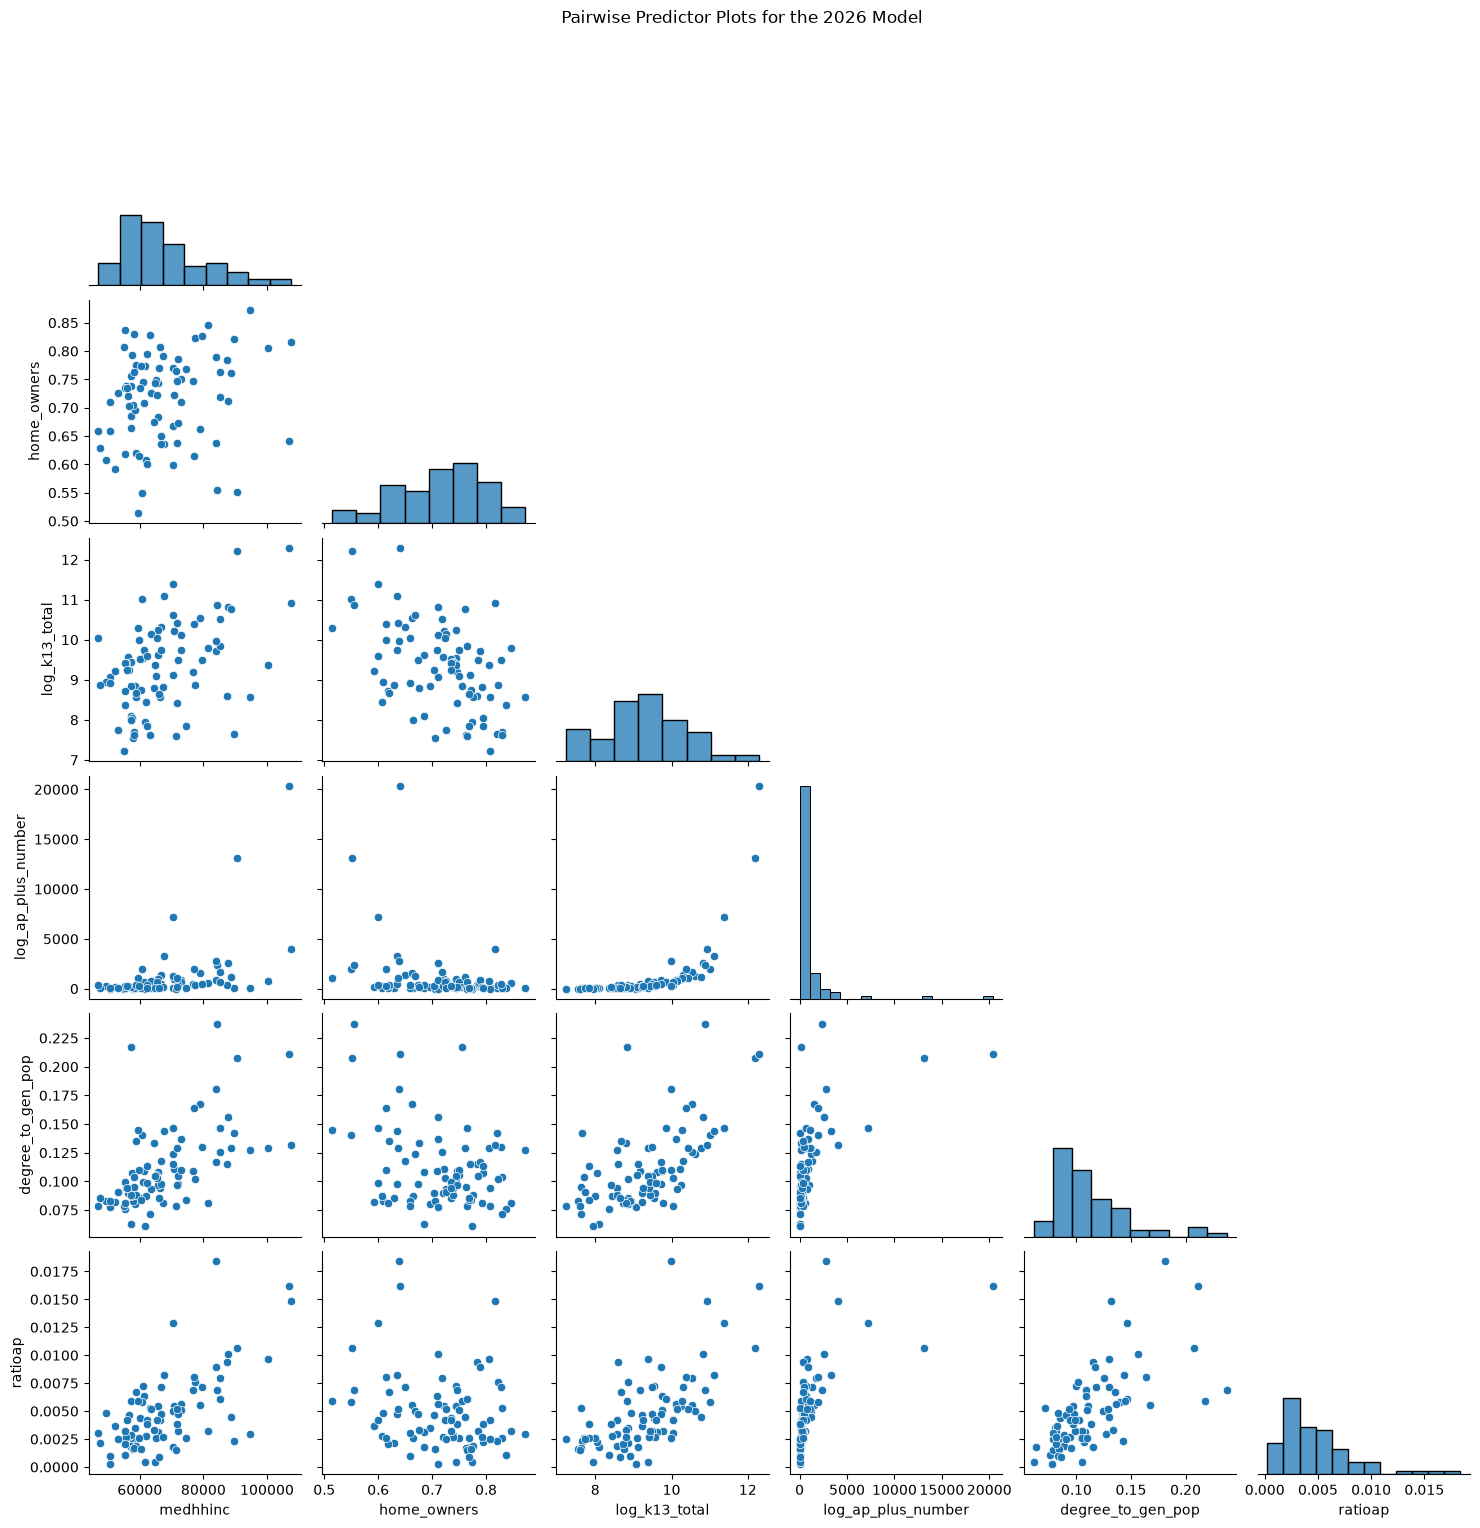

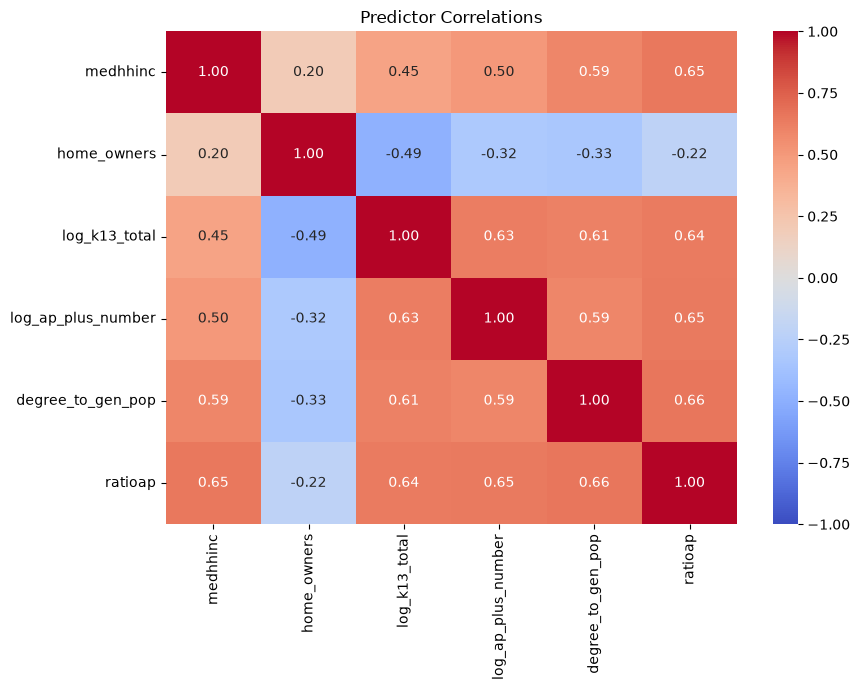

In [11]:
predictors = pd.DataFrame({
    "medhhinc": df2026["medhhinc"],
    "home_owners": df2026["home_owners"],
    "log_k13_total": log_k13_total,
    "log_ap_plus_number": df2026['ap_plus_number'],
    'degree_to_gen_pop': degree_to_gen_pop,
    'ratioap' : ratioap    
})

# Exclude blank rows, missing values, and infinities.
predictors = predictors.replace([np.inf, -np.inf], np.nan).dropna()

sns.pairplot(predictors, diag_kind="hist", corner=True)
plt.suptitle("Pairwise Predictor Plots for the 2026 Model", y=1.02)
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(
    predictors.corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Predictor Correlations")
plt.tight_layout()
plt.show()